# Applied Data Analysis and Machine Learning - Class Project
In this class project, you are supposed to work with data from the Global Preferences Survey, a globally representative dataset on risk and time preferences, positive and negative reciprocity, altruism, and trust. <br>
Further information can be found on the website (https://gps.iza.org/) and in the paper "Global Evidence on Economic Preferences" by Falk, Becker, Dohmen, Enke, Huffman, and Sunde, published in *The Quarterly Journal of Economics* 133(4): 1645–1692, 2018 (https://doi.org/10.1093/qje/qjy013).

In this class project, you will use the different techniques taught in the course: data handling, data visualization, and machine learning.

First load the necessary packages. <br>
If you want to use additional libraries you can add them to the following cell:

In [181]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
print(pd.__version__)
import seaborn as sns
sns.set()
import folium
from folium.plugins import MarkerCluster
import time
import json
import geopandas as gpd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

2.2.2


# Problem 1 - Data Handling

The basis of your work will be the dataset containing information on and preferences of individuals (`individual_new.csv`):
- *country*: Country name
- *isocode*: Three-letter country codes ISO 3166-1 alpha-3
- *ison*: Three-digit country codes ISO 3166-1 numeric
- *region*: Subnational region of interview
- *language*: Interview language
- *date*: Interview date
- *id*: Respondent ID
- *wgt*: Sampling weight of the observation
- *patience*: Level of patience
- *risktaking*: Willingness to take risks
- *posrecip*: Positive reciprocity
- *negrecip*: Negative reciprocity
- *altruism*: Level of altruism
- *trust*: Level of trust
- *subj_math_skills*: Subjective math skills from 0 to 10
- *female*: Indicator for female
- *age*: Age

Note that the variables *patience*, *risktaking*, *posrecip*, *negrecip*, *altruism* and *trust* are normalized to mean 0 and standard deviation 1.

In [182]:
data = pd.read_csv("individual_new.csv", sep=",")
data

## Solution 1.a.

>a)
Explore the dataset, for example:
- Check for missing values
- Check for the correct datatype of the variables


First we are focusing on the corect datatype of the variables, so we use the following command to see the data type of each variable:

In [183]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80337 entries, 0 to 80336
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   country           80337 non-null  object 
 1   isocode           80337 non-null  object 
 2   ison              80337 non-null  int64  
 3   region            79329 non-null  object 
 4   language          80337 non-null  object 
 5   date              79822 non-null  object 
 6   id                80337 non-null  int64  
 7   wgt               80337 non-null  float64
 8   patience          79730 non-null  float64
 9   risktaking        79703 non-null  float64
 10  posrecip          80189 non-null  float64
 11  negrecip          78536 non-null  float64
 12  altruism          79903 non-null  float64
 13  trust             78774 non-null  float64
 14  subj_math_skills  79211 non-null  float64
 15  female            80337 non-null  int64  
 16  age               80061 non-null  object

Given the information about the data set and the data previsualization we create the next table about the data types of the variables:

| Variable         | Expected Data Type                                          | Current Data Type | Is correct? |
|------------------|-------------------------------------------------------------|-------------------|-------------|
| country          | string                                                      | string (object)   | yes         |
| isocode          | string                                                      | string (object)   | yes         |
| ison             | integer                                                     | int64             | yes         |
| region           | string                                                      | string (object)   | yes         |
| language         | string                                                      | string (object)   | yes         |
| date             | date                                                        | string (object)   | no          |
| id               | integer                                                     | int64             | yes         |
| wgt              | float                                                       | float64           | yes         |
| patience         | float                                                       | float64           | yes         |
| risktaking       | float                                                       | float64           | yes         |
| posrecip         | float                                                       | float64           | yes         |
| negrecip         | float                                                       | float64           | yes         |
| altruism         | float                                                       | float64           | yes         |
| trust            | float                                                       | float64           | yes         |
| subj_math_skills | float (allowing for continous answers like 5.5 or 7.32)     | float64           | yes         |
| female           | integer (review that the values are only 1 or 0) or boolean | integer           | yes         |
| age              | integer                                                     | string (object)   | no          |


So we detect two wrong datatypes, data and age. To correct this we would first make a try to convert to date type the variable date

In [184]:
datetest = pd.to_datetime(data["date"])

/tmp/ipython-input-2386193836.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetest = pd.to_datetime(data["date"])


In this way we noticed that pandas can't infer correctly the format so we are giving an explicit format in the command:

In [185]:
data['date'] = pd.to_datetime(data["date"], format="%d %b %y")
print(data['date'])

0       2012-03-07
1       2012-03-08
2       2012-03-08
3       2012-03-07
4       2012-03-07
           ...    
80332   2012-11-22
80333   2012-11-22
80334   2012-11-22
80335   2012-11-22
80336   2012-11-22
Name: date, Length: 80337, dtype: datetime64[ns]


Now we are trying with the column age

As some records have the value "90 99+" Wich seems to represent an age higher than 99. We replace these values for a value of 100 correct the datatype


In [186]:
data['age'] = pd.to_numeric(data["age"].replace("99 99+", 100), errors='coerce')

In [187]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80337 entries, 0 to 80336
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   country           80337 non-null  object        
 1   isocode           80337 non-null  object        
 2   ison              80337 non-null  int64         
 3   region            79329 non-null  object        
 4   language          80337 non-null  object        
 5   date              79822 non-null  datetime64[ns]
 6   id                80337 non-null  int64         
 7   wgt               80337 non-null  float64       
 8   patience          79730 non-null  float64       
 9   risktaking        79703 non-null  float64       
 10  posrecip          80189 non-null  float64       
 11  negrecip          78536 non-null  float64       
 12  altruism          79903 non-null  float64       
 13  trust             78774 non-null  float64       
 14  subj_math_skills  7921

Now let's focus on the missing values, for that first recall the info about the missing values:

In [188]:
print(data.isnull().sum())
data.isnull().any(axis=0)

country                0
isocode                0
ison                   0
region              1008
language               0
date                 515
id                     0
wgt                    0
patience             607
risktaking           634
posrecip             148
negrecip            1801
altruism             434
trust               1563
subj_math_skills    1126
female                 0
age                  276
dtype: int64


,0
country,False
isocode,False
ison,False
region,True
language,False
date,True
id,False
wgt,False
patience,True
risktaking,True


Now we check the percentage of the missing values

In [189]:
#Check percentage
print("\nPercentage of missing values per column:")
print(data.isnull().mean() * 100)
# Check duplicates
print("\nNumber of duplicate rows:", data.duplicated().sum())


Percentage of missing values per column:
country             0.000000
isocode             0.000000
ison                0.000000
region              1.254715
language            0.000000
date                0.641050
id                  0.000000
wgt                 0.000000
patience            0.755567
risktaking          0.789176
posrecip            0.184224
negrecip            2.241806
altruism            0.540224
trust               1.945554
subj_math_skills    1.401596
female              0.000000
age                 0.343553
dtype: float64

Number of duplicate rows: 0


For the training of our model is recommended to replace the missing values instead of droping the column. For categorial values we fill them with the most common value (mode). For numerical values we fill them with the mean.

In [190]:
#region
data['region'] = data['region'].fillna(data['region'].mode()[0])
#date
data['date'] = data['date'].fillna(data['date'].mode()[0])
#age
data['age'] = data['age'].fillna(data['age'].mode()[0])

# Fill numeric (float64) columns with missing values using the median
for col in data.select_dtypes(include='float64').columns:
    if data[col].isnull().any():
        data[col] = data[col].fillna(data[col].median())

Now we check that the dataset has no missing values.

In [191]:
print(data.isnull().sum())
data.isnull().any(axis=0)

country             0
isocode             0
ison                0
region              0
language            0
date                0
id                  0
wgt                 0
patience            0
risktaking          0
posrecip            0
negrecip            0
altruism            0
trust               0
subj_math_skills    0
female              0
age                 0
dtype: int64


,0
country,False
isocode,False
ison,False
region,False
language,False
date,False
id,False
wgt,False
patience,False
risktaking,False


## Solution 1.b

>b)
- Identify potential correlations between different variables
- Are there regional differences in certain preferences?

For the correlation between different values we establish behavioural preference variables and create a Heatmap in order to take conclusions.

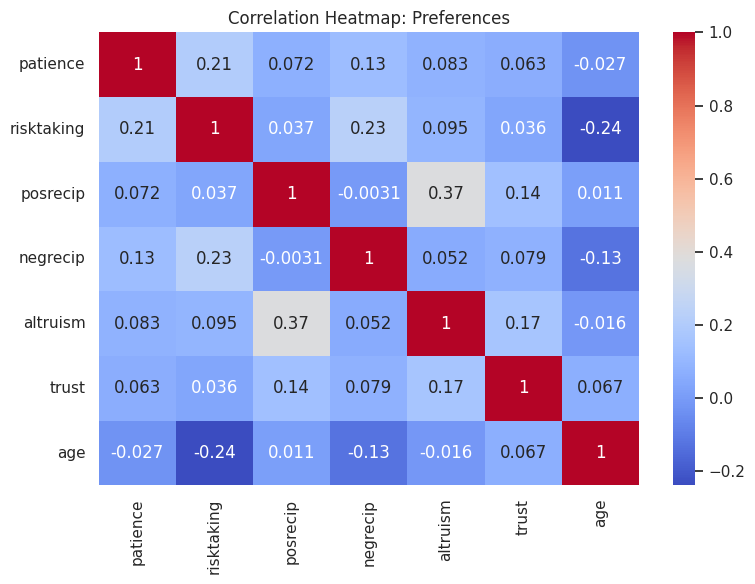

In [192]:
# List of preference variables
pref_vars = ['patience', 'risktaking', 'posrecip', 'negrecip', 'altruism', 'trust', 'age']
# --- PART 1: Correlation between preference variables ---

# Compute correlation matrix
corr_matrix = data[pref_vars].corr()

# Plot heatmap of correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', xticklabels=pref_vars, yticklabels=pref_vars)
plt.title("Correlation Heatmap: Preferences")
plt.tight_layout()
plt.show()


summary of key correlations

- altruism and posrecip: 0.38 (moderately positive)
- risktaking and negrecip: 0.23
- altruism and trust: 0.17
- Other correlations are generally weak.

We use the same behavioural “preference” variables to find regional differences. Here we want to examine whether the average level of each preference variable differs across regions.

                   patience  risktaking  posrecip  negrecip  altruism  \
region                                                                  
El-Garbia         -0.701462   -0.572816  0.752047 -0.332554  0.820039   
Khon Kaen         -0.089963   -0.224458  0.523180  0.270715 -0.731638   
Rajasthan         -0.398357   -0.508420  0.134696  0.503043 -0.518783   
Republic of Altay -0.399462   -0.618106  0.142579 -0.166904  0.242655   
Toronto CMA        0.806351    0.144028  0.210921 -0.028750  0.364258   

                      trust        age  
region                                  
El-Garbia          0.710187  37.670588  
Khon Kaen          0.828880  39.866667  
Rajasthan         -0.784761  37.355705  
Republic of Altay -0.051098  49.577465  
Toronto CMA        0.356918  46.372414  


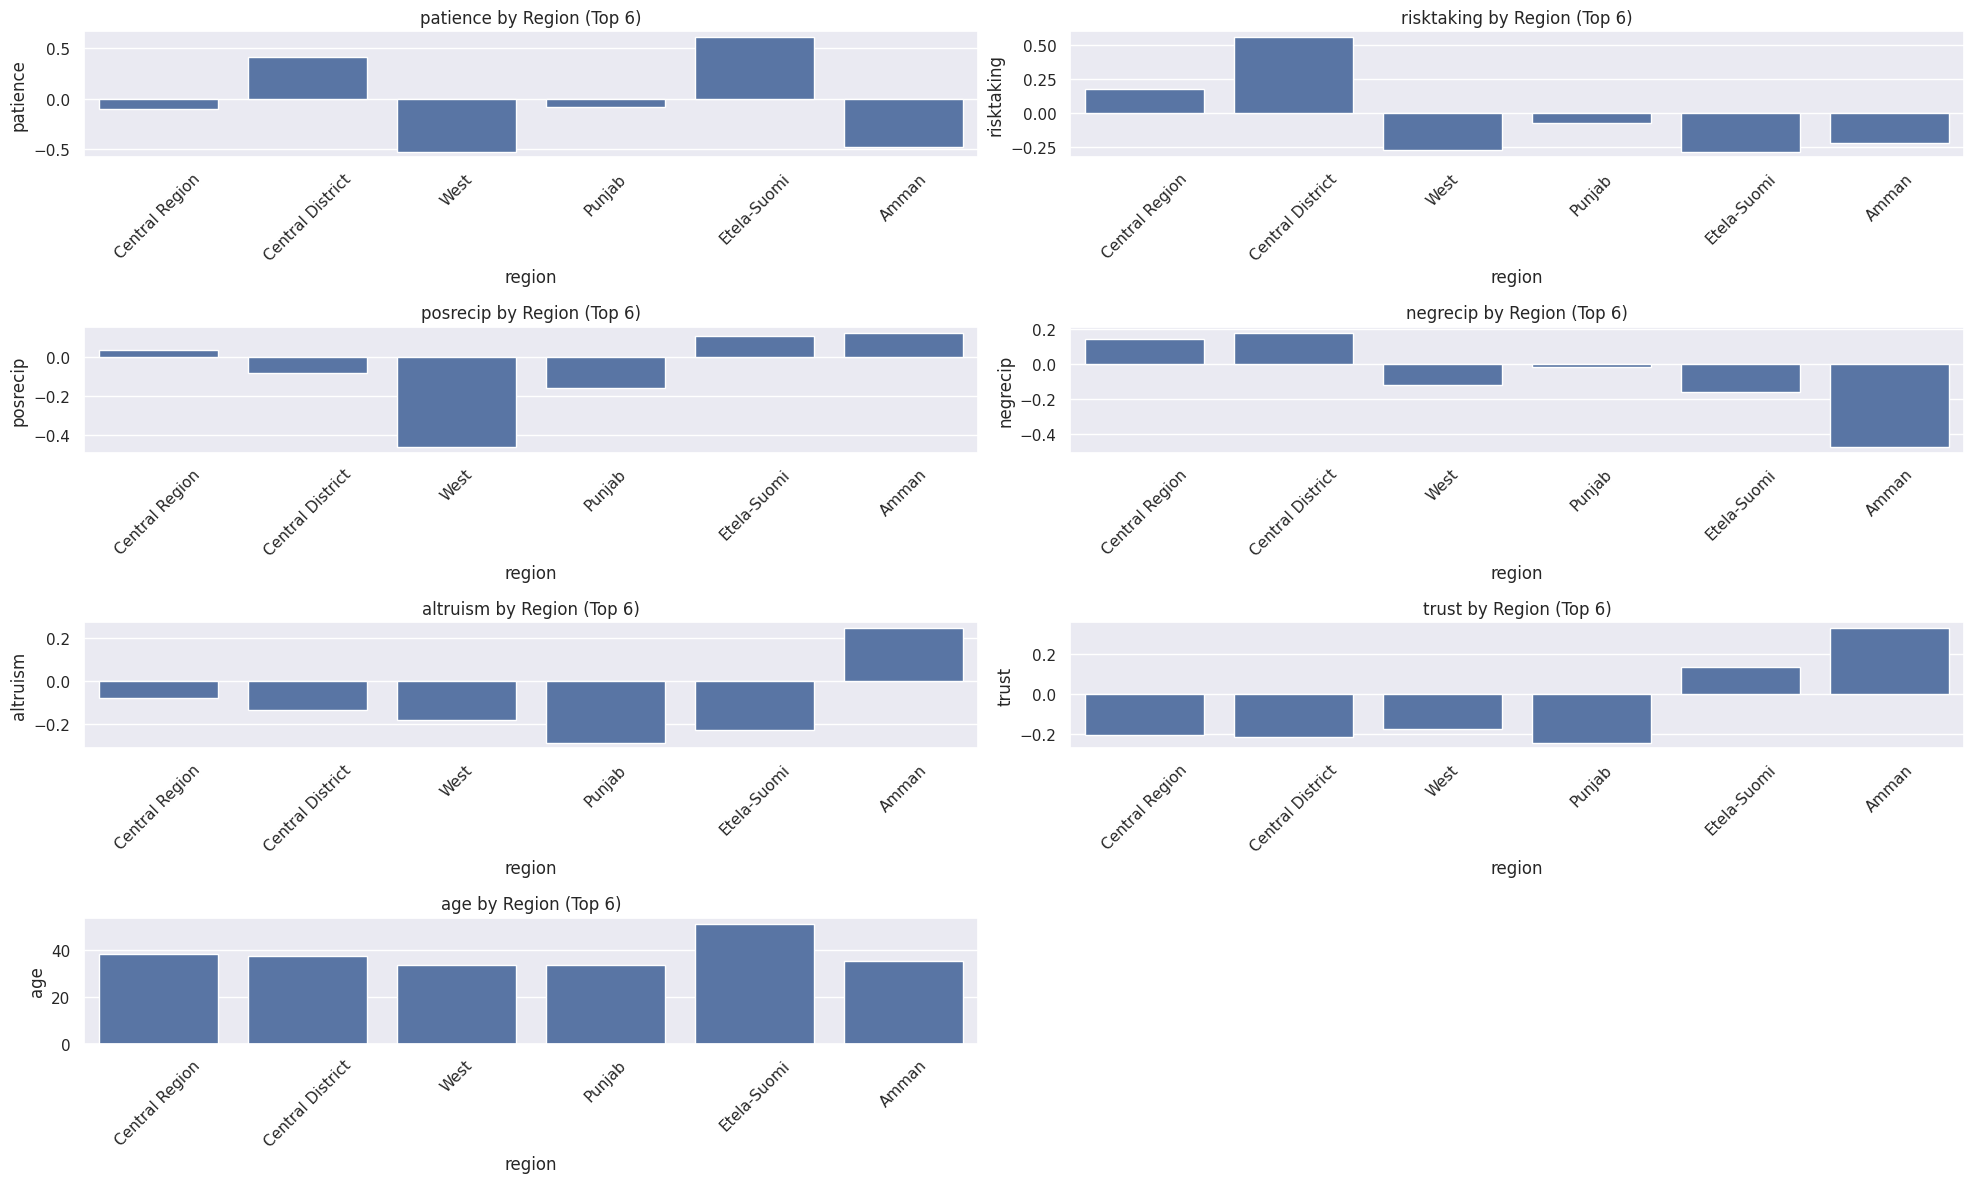

In [193]:
# Compute mean preference scores by region
regional_means = data.groupby('region')[pref_vars].mean()

# Display the first few rows of the summary
print(regional_means.head())

# Select a subset of regions as there are many we are taking a sample of top 6 size
top_regions = data['region'].value_counts().head(6).index

# Boxplots: Each preference variable across top regions
plt.figure(figsize=(20, 12))
for i, var in enumerate(pref_vars):
    plt.subplot(4, 2, i+1)
    sns.barplot(x=regional_means.loc[top_regions].index,
            y=regional_means.loc[top_regions][var])
    plt.title(f"{var} by Region (Top 6)")
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Regional Differences:
Boxplots indicate clear regional differences in several preferences —
especially in trust, altruism, and risktaking.
This suggests that cultural or regional contexts may influence these behavioral traits.

# Problem 2 - Data Visualization

## Solution 2.a.
>To get some first insights in the data, create meaningful plots on preferences, countries, demographics, etc. <br>
You can use any kind that you deem useful: histograms, line plots, etc.

We first plot the distribution of each prefrerence.

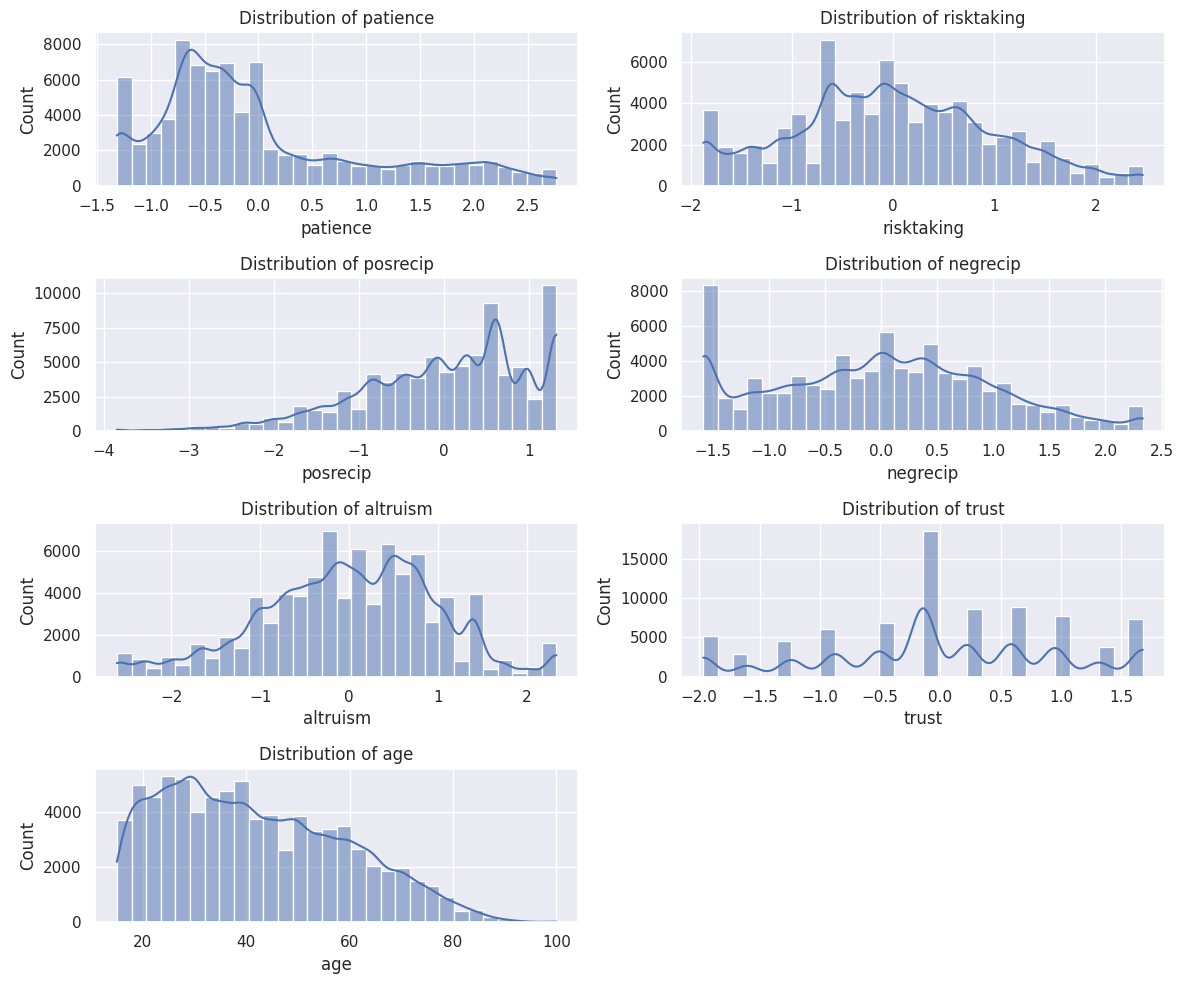

In [194]:
# 1. Histograms of preference variables
plt.figure(figsize=(12, 10))
for i, var in enumerate(pref_vars):
    plt.subplot(4, 2, i+1)
    sns.histplot(data[var], kde=True, bins=30)
    plt.title(f'Distribution of {var}')
plt.tight_layout()
plt.show()

Now we compare preferences across demographic groups.

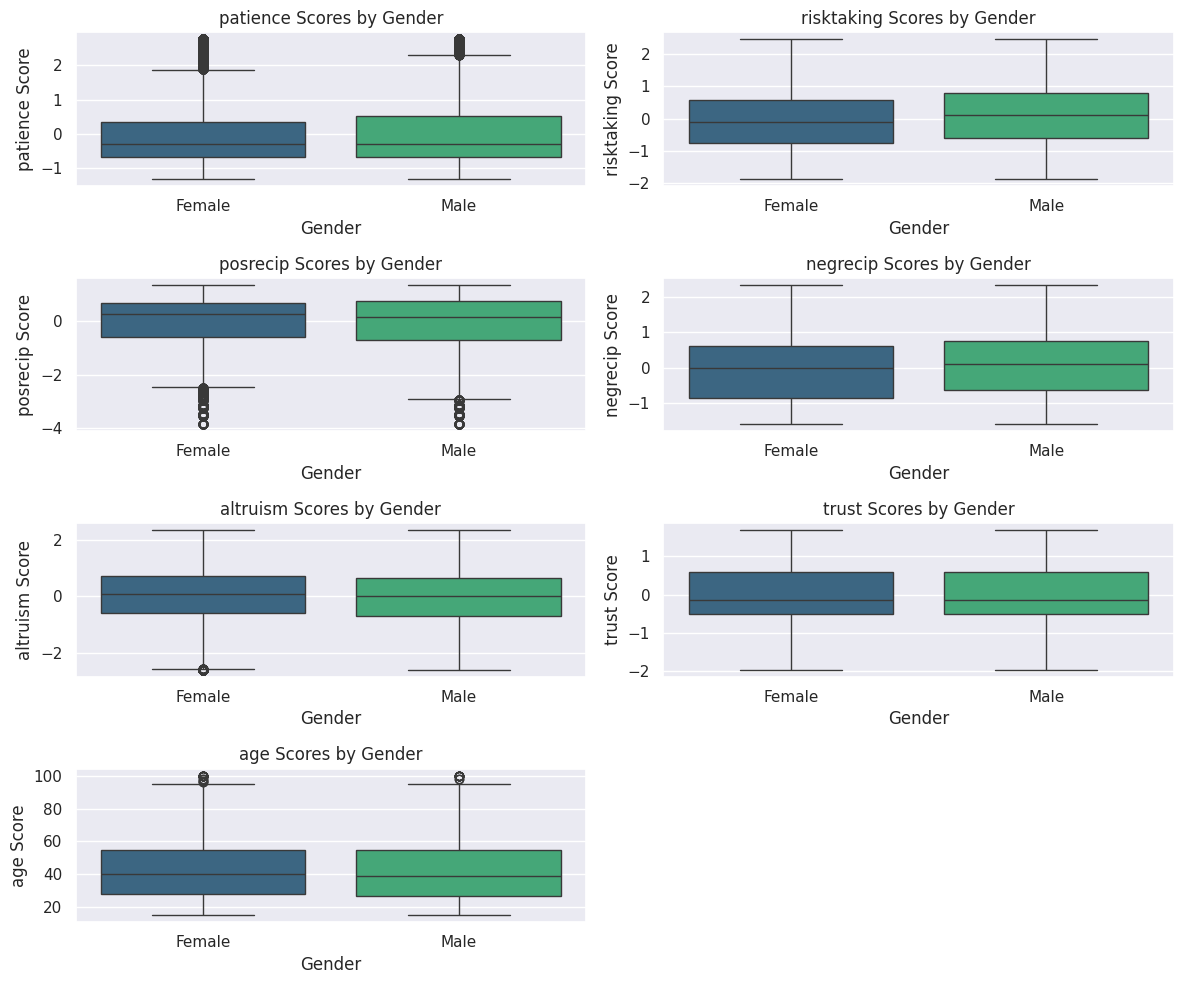

In [195]:
# 1. Histograms of preference variables
data['gender_label'] = data['female'].map({0: 'Male', 1: 'Female'})
plt.figure(figsize=(12, 10))
for i, var in enumerate(pref_vars):
    plt.subplot(4, 2, i+1)
    sns.boxplot(x='gender_label', y=var, data=data, hue='gender_label', palette='viridis', legend=False)
    plt.title(f'{var} Scores by Gender')
    plt.xlabel('Gender')
    plt.ylabel(f'{var} Score')
plt.tight_layout()
plt.show()

Avarage preferences across demographic groups. For this we calculate the average trust score for the 10 countries with the largest sample sizes in the dataset.

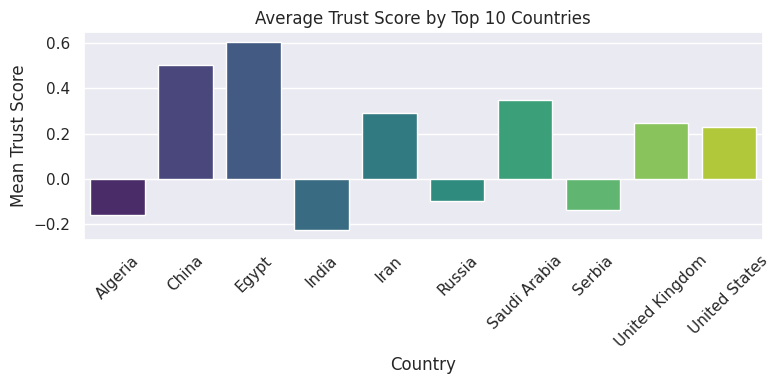

In [196]:
# Bar chart of mean trust for the top 10 countries by sample size
top_countries = data['country'].value_counts().head(10).index
mean_trust = data[data['country'].isin(top_countries)].groupby('country')['trust'].mean().reset_index()
plt.figure(figsize=(8,4))
sns.barplot(x='country', y='trust',  hue='country', data=mean_trust, palette='viridis', legend=False)
plt.title('Average Trust Score by Top 10 Countries')
plt.xticks(rotation=45)
plt.xlabel('Country')
plt.ylabel('Mean Trust Score')
plt.tight_layout()
plt.show()

We take a look at the age distribution.

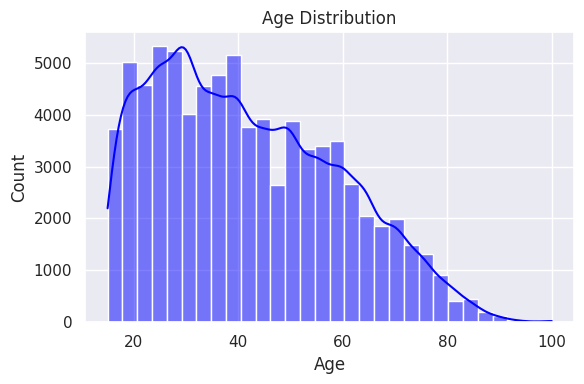

In [197]:
# Histogram of age distribution
plt.figure(figsize=(6,4))
sns.histplot(data['age'].dropna(), bins=30, kde=True, color='blue')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## Solution 2.b.
>Pick at least one preference measure. <br>
For this measure, create an interactive map with `folium` that tells you the average in the country in the given year. <br>
*Hint 1: Be cautious with country names.* <br>
*Hint 2: Consider the sampling weights when taking the (weighted) average.*

In [198]:
#Extract year
data['year'] = data['date'].dt.year

# Filter files
df_clean = (
    data
    .dropna(subset=['country', 'trust', 'wgt', 'year'])
    .assign(
        trust=lambda d: pd.to_numeric(d['trust'], errors='coerce'),
        wgt=lambda d: pd.to_numeric(d['wgt'], errors='coerce')
    )
    .dropna(subset=['trust','wgt'])
)


# Weighted mean

def wavg_trust(x):
    # x is 'trust' series wights aligned by index
    w = df_clean.loc[x.index, 'wgt']
    return np.average(x, weights=w)

avg_trust = (
    df_clean
    .groupby(['country', 'year'], as_index=False)
    .agg(weighted_avg_trust=('trust', wavg_trust))
)

# coordenates data
coords_data = {
    "Afghanistan": (33.9391, 67.7100),
    "Algeria": (28.0339, 1.6596),
    "Argentina": (-38.4161, -63.6167),
    "Australia": (-25.2744, 133.7751),
    "Austria": (47.5162, 14.5501),
    "Bangladesh": (23.6850, 90.3563),
    "Belarus": (53.7098, 27.9534),
    "Belgium": (50.8503, 4.3517),
    "Bolivia": (-16.2902, -63.5887),
    "Bosnia Herzegovina": (43.9159, 17.6791),
    "Botswana": (-22.3285, 24.6849),
    "Brazil": (-14.2350, -51.9253),
    "Bulgaria": (42.7339, 25.4858),
    "Cambodia": (12.5657, 104.9910),
    "Cameroon": (7.3697, 12.3547),
    "Canada": (56.1304, -106.3468),
    "Chile": (-35.6751, -71.5430),
    "China": (35.8617, 104.1954),
    "Colombia": (4.5709, -74.2973),
    "Costa Rica": (9.7489, -83.7534),
    "Croatia": (45.1000, 15.2000),
    "Czech Republic": (49.8175, 15.4730),
    "Denmark": (56.2639, 9.5018),
    "Dominican Republic": (18.7357, -70.1627),
    "Ecuador": (-1.8312, -78.1834),
    "Egypt": (26.8206, 30.8025),
    "El Salvador": (13.7942, -88.8965),
    "Estonia": (58.5953, 25.0136),
    "Finland": (61.9241, 25.7482),
    "France": (46.6034, 1.8883),
    "Georgia": (42.3154, 43.3569),
    "Germany": (51.1657, 10.4515),
    "Ghana": (7.9465, -1.0232),
    "Greece": (39.0742, 21.8243),
    "Guatemala": (15.7835, -90.2308),
    "Haiti": (18.9712, -72.2852),
    "Honduras": (13.2000, -87.2000),
    "Hungary": (47.1625, 19.5033),
    "Iceland": (64.9631, -19.0208),
    "India": (20.5937, 78.9629),
    "Indonesia": (-0.7893, 113.9213),
    "Iran": (32.4279, 53.6880),
    "Iraq": (33.2232, 43.6793),
    "Ireland": (53.3331, -6.2489),
    "Israel": (31.0461, 34.8516),
    "Italy": (41.8719, 12.5674),
    "Japan": (36.2048, 138.2529),
    "Jordan": (30.5852, 36.2384),
    "Kazakhstan": (48.0196, 66.9237),
    "Kenya": (-0.0236, 37.9062),
    "Kuwait": (29.3759, 47.9774),
    "Latvia": (56.8796, 24.6032),
    "Lebanon": (33.8547, 35.8623),
    "Lithuania": (55.1694, 23.8813),
    "Luxembourg": (49.6117, 6.1319),
    "Malaysia": (4.2105, 101.9758),
    "Malawi": (-13.2543, 34.3015),
    "Mexico": (23.6345, -102.5528),
    "Moldova": (47.4116, 28.3699),
    "Morocco": (31.7917, -7.0926),
    "Netherlands": (52.1326, 5.2913),
    "Nicaragua": (12.8654, -85.2072),
    "Nigeria": (9.0820, 8.6753),
    "Pakistan": (30.3753, 69.3451),
    "Peru": (-9.1900, -75.0152),
    "Philippines": (12.8797, 121.7740),
    "Poland": (51.9194, 19.1451),
    "Portugal": (39.3999, -8.2245),
    "Romania": (45.9432, 24.9668),
    "Russia": (61.5240, 105.3188),
    "Rwanda": (-1.9403, 29.8739),
    "Saudi Arabia": (23.8859, 45.0792),
    "Serbia": (44.0165, 21.0059),
    "Singapore": (1.3521, 103.8198),
    "Slovakia": (48.6690, 19.6990),
    "South Africa": (-30.5595, 22.9375),
    "South Korea": (35.9078, 127.7669),
    "Spain": (40.4637, -3.7492),
    "Sri Lanka": (7.8731, 80.7718),
    "Suriname": (3.9193, -56.0278),
    "Sweden": (60.1282, 18.6435),
    "Switzerland": (46.8182, 8.2275),
    "Tanzania": (-6.3690, 34.8888),
    "Thailand": (15.8700, 100.9925),
    "Turkey": (38.9637, 35.2433),
    "Uganda": (1.3733, 32.2903),
    "Ukraine": (48.3794, 31.1656),
    "United Arab Emirates": (23.4241, 53.8478),
    "United Kingdom": (55.3781, -3.4360),
    "United States": (37.0902, -95.7129),
    "Venezuela": (6.4238, -66.5897),
    "Vietnam": (14.0583, 108.2772),
    "Zimbabwe": (-19.0154, 29.1549),
}

# Function to handle country name variations
def coords_key(country_name):
    """Maps country names to keys in coords_data."""
    # Simple mapping, more complex logic might be needed for other datasets
    return country_name.strip()

avg_trust = avg_trust.assign(
    lat=lambda d: d['country'].apply(lambda x: coords_data.get(coords_key(x), (None, None))[0]),
    lon=lambda d: d['country'].apply(lambda x: coords_data.get(coords_key(x), (None, None))[1]),
)

# Filter out rows where coordinates were not found
avg_trust_map = avg_trust.dropna(subset=['lat', 'lon'])

# Create map
m = folium.Map(location=[20, 0], zoom_start=2)
marker_cluster = MarkerCluster().add_to(m)

for _, row in avg_trust_map.iterrows():
    popup = (
        f"<b>Country:</b> {row['country']}"
        f"<br><b>Year:</b> {int(row['year'])}"
        f"<br><b>Weighted Trust:</b> {row['weighted_avg_trust']:.2f}"
    )
    folium.Marker([row['lat'], row['lon']], popup=popup).add_to(marker_cluster)

m.save("interactive_trust_map.html")
m

# Problem 3 - Supervised Machine Learning

## Solution 3.a.
>Try to predict the subjects' countries of origin using the information provided. <br>
Report the performance measures for different predictor variables.

We use behavioural measures for the prediction using the same data set as it was alreaady cleaned

In [199]:
# Restrict to the 10 most frequent countries to keep the problem manageable
top_countries = data['country'].value_counts().head(10).index.tolist()
subset = data[data['country'].isin(top_countries)].copy()
# Drop rows with missing values in key columns
features = ['patience', 'risktaking', 'posrecip', 'negrecip', 'altruism', 'trust']

Countries are labels, so we use LabelEncoder to convert them into integer codes.

In [200]:
# Features (X) and target (y)
X = subset[features]
y = subset['country']
# Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42, stratify=y)


Definition of models, training and accuracy evaluation

In [201]:
models = {
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}
# Train and evaluate each model
for name, model in models.items():
    clf = Pipeline([
        ('model', model)
    ])
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    print(f'{name}: accuracy={acc:.3f}, macro‑F1={f1:.3f}')

KNN (k=5): accuracy=0.341, macro‑F1=0.286
Decision Tree: accuracy=0.292, macro‑F1=0.265
Random Forest: accuracy=0.419, macro‑F1=0.362


Next we tested whether demographic and cognitive variables (age, gender, math skills) offered better predictive power for the same 10 countries.<br>
We apply the same previous process


In [202]:
features = ['female', 'age', 'subj_math_skills']
X = subset[features]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Preprocess: impute missing numeric values and scale features
preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
models = {
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}
# Train and evaluate each model
for name, model in models.items():
    clf = Pipeline([
        ('model', model)
    ])
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    print(f'{name}: accuracy={acc:.3f}, macro‑F1={f1:.3f}')

KNN (k=5): accuracy=0.191, macro‑F1=0.159
Decision Tree: accuracy=0.208, macro‑F1=0.160
Random Forest: accuracy=0.209, macro‑F1=0.164


Finally, we removed the restriction to the top 10 countries and trained on all available countries using behavioral variables. As expected, the accuracy dropped sharply due to the higher number of target classes and increased class imbalance

In [203]:
# Drop rows with missing values in key columns
features = ['patience', 'risktaking', 'posrecip', 'negrecip', 'altruism', 'trust']

# Features (X) and target (y)
X = data[features]
y = data['country']
# Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42, stratify=y)

# Preprocess: impute missing numeric values and scale features
preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
models = {
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}
# Train and evaluate each model
for name, model in models.items():
    clf = Pipeline([
        ('model', model)
    ])
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    print(f'{name}: accuracy={acc:.3f}, macro‑F1={f1:.3f}')

KNN (k=5): accuracy=0.073, macro‑F1=0.070
Decision Tree: accuracy=0.082, macro‑F1=0.080
Random Forest: accuracy=0.131, macro‑F1=0.120


Restricting the classification task to the most frequent countries improves performance compared to including all countries, due to reduced class imbalance and fewer classes. Among the tested feature sets, behavioral variables provided better predictive power than demographic and cognitive ones.


## Solution 3.b.
>Try to fill the gaps in the preference measures in the data using appropriate prediction models.

We filter again the most repeated countries in the dataset to fill the gaps

In [204]:
# Load dataset
data3b = pd.read_csv("individual_new.csv")

# Restrict to the 10 most frequent countries to keep the problem manageable
top_countries = data3b['country'].value_counts().head(10).index.tolist()
subset = data3b[data3b['country'].isin(top_countries)].copy()

We clean the dataset and iterate over each preference to predict the missing values.<br>
We use RandomForestRegressor and behavioural variables as they reached the better results in the previous tests

In [205]:
# Convert 'age' to numeric
subset['age'] = pd.to_numeric(subset['age'], errors='coerce')

# List of preference measures
pref_vars = ['patience', 'risktaking', 'posrecip', 'negrecip', 'altruism', 'trust']


# Track model performance
results = {}

# Loop through each preference variable
for target in pref_vars:
    print(f"\n--- Predicting missing values for: {target} ---")

    # Use other preference variables + extra features as predictors
    predictors = [var for var in pref_vars if var != target]

    # Ensure predictors are clean
    df_model = subset[predictors + [target]].copy()

    # Drop rows where predictors are missing
    df_model = df_model.dropna(subset=predictors)

    # Split into known and missing target
    known = df_model[df_model[target].notnull()]
    missing = df_model[df_model[target].isnull()]

    # Train model only if there are missing values to predict
    if not missing.empty:
        X_train = known[predictors]
        y_train = known[target]
        X_missing = missing[predictors]

        # Train model
        model = RandomForestRegressor(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)

        # Predict missing values
        predicted = model.predict(X_missing)

        # Fill back into original DataFrame
        subset.loc[missing.index, target] = predicted

        # Evaluate model
        X_test, X_val, y_test, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
        y_pred = model.predict(X_val)
        mse = mean_squared_error(y_val, y_pred)
        results[target] = mse
        print(f"Filled {len(predicted)} missing values for '{target}'. MSE on validation: {mse:.4f}")
    else:
        print(f"No missing values found for '{target}'.")

# Final output
print("\n--- Mean Squared Error for Each Imputed Variable ---")
for var, mse in results.items():
    print(f"{var}: MSE = {mse:.4f}")



--- Predicting missing values for: patience ---
Filled 62 missing values for 'patience'. MSE on validation: 0.1498

--- Predicting missing values for: risktaking ---
Filled 97 missing values for 'risktaking'. MSE on validation: 0.1493

--- Predicting missing values for: posrecip ---
Filled 9 missing values for 'posrecip'. MSE on validation: 0.1122

--- Predicting missing values for: negrecip ---
Filled 169 missing values for 'negrecip'. MSE on validation: 0.1280

--- Predicting missing values for: altruism ---
Filled 22 missing values for 'altruism'. MSE on validation: 0.1258

--- Predicting missing values for: trust ---
Filled 145 missing values for 'trust'. MSE on validation: 0.1373

--- Mean Squared Error for Each Imputed Variable ---
patience: MSE = 0.1498
risktaking: MSE = 0.1493
posrecip: MSE = 0.1122
negrecip: MSE = 0.1280
altruism: MSE = 0.1258
trust: MSE = 0.1373


The models successfully imputed all missing values for each preference measure, with validation mean squared errors (MSE) ranging from 0.1122 (posrecip) to 0.1498 (patience). These relatively low MSE values suggest that the chosen approach was effective at capturing relationships between the behavioral variables and generating plausible estimates for the missing data.

# Problem 4 - Unsupervised Machine Learning

## Solution 4.a.
>Use the preference measures to cluster *individuals*. <br>
Which is the optimal number of clusters? <br>
Can you provide an intuition for the clusters you identified?

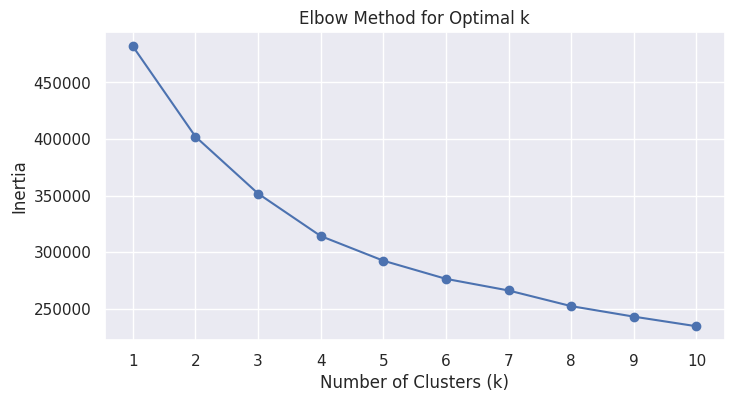

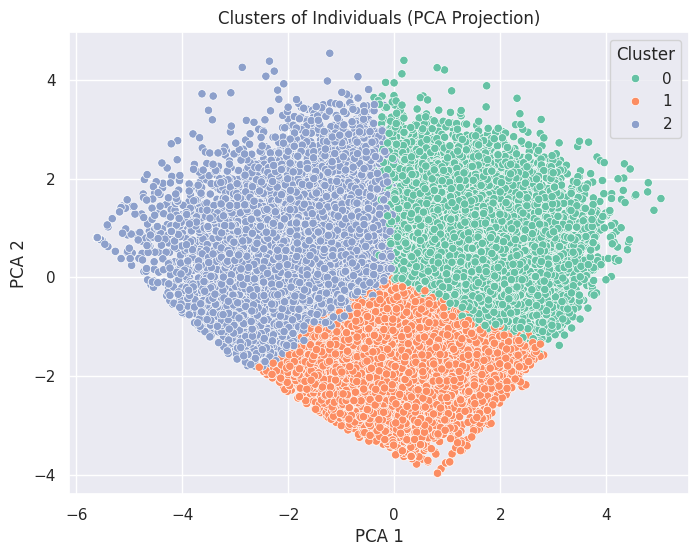


Cluster Centroids (average scores on preferences):
   patience  risktaking  posrecip  negrecip  altruism  trust
0      0.65        0.63      0.28      0.67      0.30   0.23
1     -0.40       -0.49      0.57     -0.64      0.51   0.16
2     -0.34       -0.22     -0.90     -0.11     -0.87  -0.43


In [206]:
# Define preference variables
pref_vars = ['patience', 'risktaking', 'posrecip', 'negrecip', 'altruism', 'trust']

# Drop rows with missing preference data
df_cluster = data[pref_vars].dropna()

# Standardize data for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

# Elbow Method to find optimal number of clusters
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Choose k as 3 after looking for the elbow graph and the PCA results
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
df_cluster['cluster'] = kmeans_final.fit_predict(X_scaled)

# Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_cluster['cluster'], palette='Set2')
plt.title('Clusters of Individuals (PCA Projection)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

cluster_centers = pd.DataFrame(scaler.inverse_transform(kmeans_final.cluster_centers_),
                               columns=pref_vars)
print("\nCluster Centroids (average scores on preferences):")
print(cluster_centers.round(2))


Interpretation of results

Using the elbow method and PCA visualization, the optimal number of clusters was set to k = 3. <br>
The three clusters differ meaningfully in their standardized preference profiles:

- Cluster 0: Lower than average altruism, trust, and positive reciprocity. Potentially representing less cooperative individuals.
- Cluster 1: Moderate altruism and trust, higher positive reciprocity, but lower risktaking. Possibly more cautious and selective in cooperation.

- Cluster 2: Above-average scores across most preferences, especially patience, risktaking, and negative reciprocity. Potentially more proactive, assertive, and socially engaged individuals.

These clusters may reflect distinct behavioral archetypes present in the sample, ranging from more individualistic to more cooperative orientations.

## Solution 4.b.
>Use the preference measures to cluster *countries*. <br>
Which is the optimal number of clusters? <br>
Can you provide an intuition for the clusters you identified?

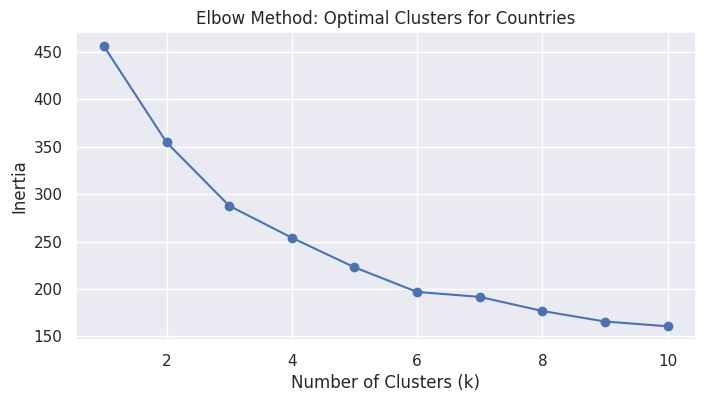

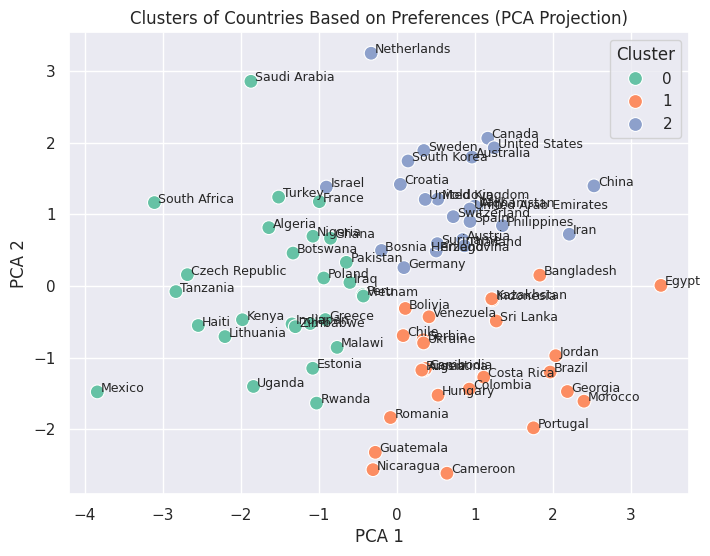


Cluster Centroids (Preference Profiles by Country Group):
   patience  risktaking  posrecip  negrecip  altruism  trust  cluster
0     -0.06        0.18     -0.34      0.08     -0.28  -0.19        0
1     -0.28       -0.21      0.18     -0.23      0.13  -0.03        1
2      0.35        0.03      0.15      0.14      0.11   0.19        2


In [207]:
# Define preference variables
pref_vars = ['patience', 'risktaking', 'posrecip', 'negrecip', 'altruism', 'trust']

# Group by country: average preference scores
data_country = data.groupby('country')[pref_vars].mean().reset_index()

# Standardize data for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_country[pref_vars])

# Elbow Method to find optimal number of clusters
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o')
plt.title("Elbow Method: Optimal Clusters for Countries")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# Choose k as 3 after looking for the elbow graph and the PCA results
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
data_country['cluster'] = kmeans_final.fit_predict(X_scaled)

# Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=data_country['cluster'], palette='Set2', s=100)
for i, txt in enumerate(data_country['country']):
    plt.text(X_pca[i, 0]+0.05, X_pca[i, 1], txt, fontsize=9)
plt.title("Clusters of Countries Based on Preferences (PCA Projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

centroids = pd.DataFrame(scaler.inverse_transform(kmeans_final.cluster_centers_),
                         columns=pref_vars)
centroids['cluster'] = centroids.index
print("\nCluster Centroids (Preference Profiles by Country Group):")
print(centroids.round(2))


Interpretation of results

We clustered countries using the mean of the six preference measures (standardized). The elbow curve indicates a plausible range of k = 3–4; the PCA projection shows clearer separation for k = 3, which we adopt.

The country-level clusters exhibit the following standardized profiles:

- Cluster 0: Slightly higher risktaking and negative reciprocity, but lower trust, altruism, and positive reciprocity. Less cooperative and slightly more competitive countries.

- Cluster 1: Higher positive reciprocity and altruism, with lower risktaking and patience. More cooperative but cautious countries.

- Cluster 2: Above-average patience, trust, and generally positive across all measures. More balanced and favorable preference profile countries.

These clusters align with broad cultural dimensions (e.g., cooperation/trust vs. risk tolerance).